# Toronto Bike Share — June 2024 | Three visual experiments

**A.** Full-month neon route-overlap map · **B.** Rasterised cycling-corridor intensity · **C.** Observed vs GraphHopper modelled journey time.

Inputs are files already on your CSC project: `full_june_routes.sqlite`, `full_june_od_pairs.parquet`, and `bikeshare_june_2024_validated.parquet`. No API requests or new routing needed.

**Interpretation:** Routes are modelled using the OSM extract downloaded in 2026 and provisional station coordinates. Corridor intensity is rasterised *modelled* trip overlap, not observed street counts; the duration difference does not establish avoidable exposure.

In [1]:
from pathlib import Path
import sqlite3, json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LogNorm
from shapely.geometry import shape

PROJECT = Path('/scratch/project_2010417/paper3/toronto-bike-exposure')
DATA = PROJECT / 'data/processed'
OUT = PROJECT / 'outputs/maps'
OUT.mkdir(parents=True, exist_ok=True)
for fn in ['full_june_routes.sqlite','full_june_od_pairs.parquet','bikeshare_june_2024_validated.parquet']:
    assert (DATA/fn).exists(), f'Missing {DATA/fn}'
print('Project:', PROJECT)


Project: /scratch/project_2010417/paper3/toronto-bike-exposure


In [2]:
# Load the 163,026 modelled directed station-pair routes once.
pairs = pd.read_parquet(DATA/'full_june_od_pairs.parquet')
for c in ['Start_Station_Id','End_Station_Id']:
    pairs[c] = pairs[c].astype('string')
with sqlite3.connect(DATA/'full_june_routes.sqlite') as db:
    rd = pd.read_sql_query('SELECT start_id, end_id, distance_m, time_min, geometry_json FROM routes WHERE geometry_json IS NOT NULL', db)
rd = rd.merge(pairs[['Start_Station_Id','End_Station_Id','trip_count']],
              left_on=['start_id','end_id'], right_on=['Start_Station_Id','End_Station_Id'],
              validate='one_to_one', how='inner')
gdf = gpd.GeoDataFrame(rd.drop(columns='geometry_json'),
                       geometry=[shape(json.loads(v)) for v in rd.geometry_json],
                       crs='EPSG:4326').to_crs('EPSG:26917')
assert len(gdf) == len(rd)
print(f'Routed OD pairs: {len(gdf):,}; represented trips: {int(gdf.trip_count.sum()):,}')
print('Geometry types:', gdf.geometry.geom_type.value_counts().to_dict())


Routed OD pairs: 163,026; represented trips: 737,915
Geometry types: {'LineString': 163026}


## Map A — The full-month neon route map
Each unique OD path is drawn once, with width scaled gently by the recorded number of trips. Glowing overlaps are a visual technique, **not a numerical legend of network flow**.

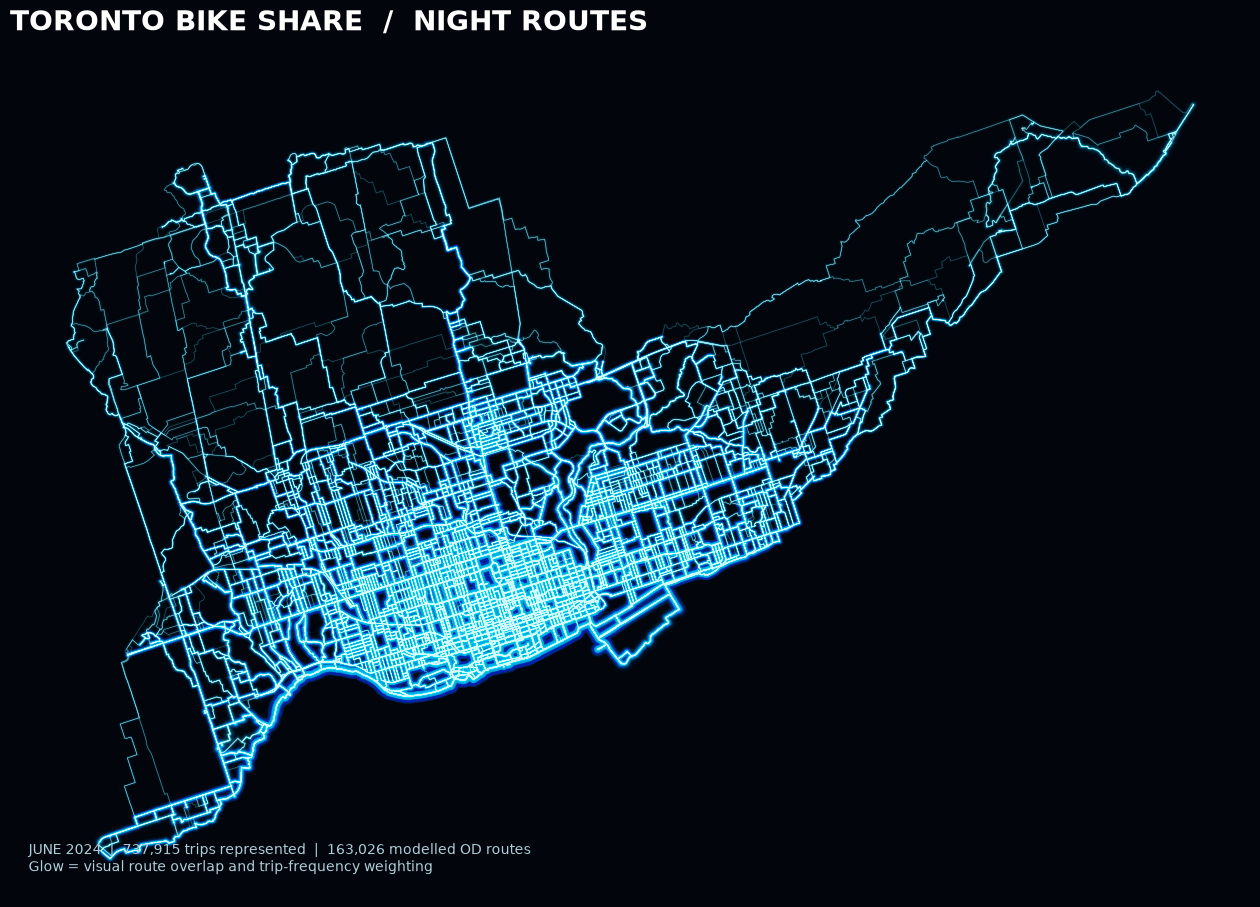

In [3]:
# This cell may use a few GB of memory for the full 163k paths.
valid = gdf.geometry.geom_type.eq('LineString')
segments = [np.asarray(geom.coords) for geom in gdf.loc[valid,'geometry']]
counts = gdf.loc[valid, 'trip_count'].to_numpy(dtype=float)
widths = 0.25 + 0.28*np.log1p(counts)
fig, ax = plt.subplots(figsize=(16,12), facecolor='#02050b')
ax.set_facecolor('#02050b')
for multiplier, opacity, colour in [(8,.012,'#0077ff'),(4,.035,'#00c8ff'),(1.6,.10,'#00e9ff'),(.55,.35,'#d7ffff')]:
    lc = LineCollection(segments, colors=colour, linewidths=widths*multiplier,
                        alpha=opacity, capstyle='round', rasterized=True)
    ax.add_collection(lc)
ax.autoscale()
ax.set_aspect('equal')
ax.set_axis_off()
ax.set_title('TORONTO BIKE SHARE  /  NIGHT ROUTES', loc='left', color='white', fontsize=20, weight='bold', pad=16)
ax.text(.015,.025, f'JUNE 2024  |  {int(gdf.trip_count.sum()):,} trips represented  |  {len(gdf):,} modelled OD routes\nGlow = visual route overlap and trip-frequency weighting',
        transform=ax.transAxes, color='#b0cfda', fontsize=10, va='bottom')
fig.savefig(OUT/'map_A_full_month_neon.png', dpi=220, facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()
plt.close(fig)


## Map B — Where modelled bicycle journeys concentrate
Rasterise each OD route with its recorded trip frequency, summing values in cells. **This is a cell-based modelled route-overlap indicator, not true street-segment traffic.** It produces a quantitative scale and can be compared with Map A.

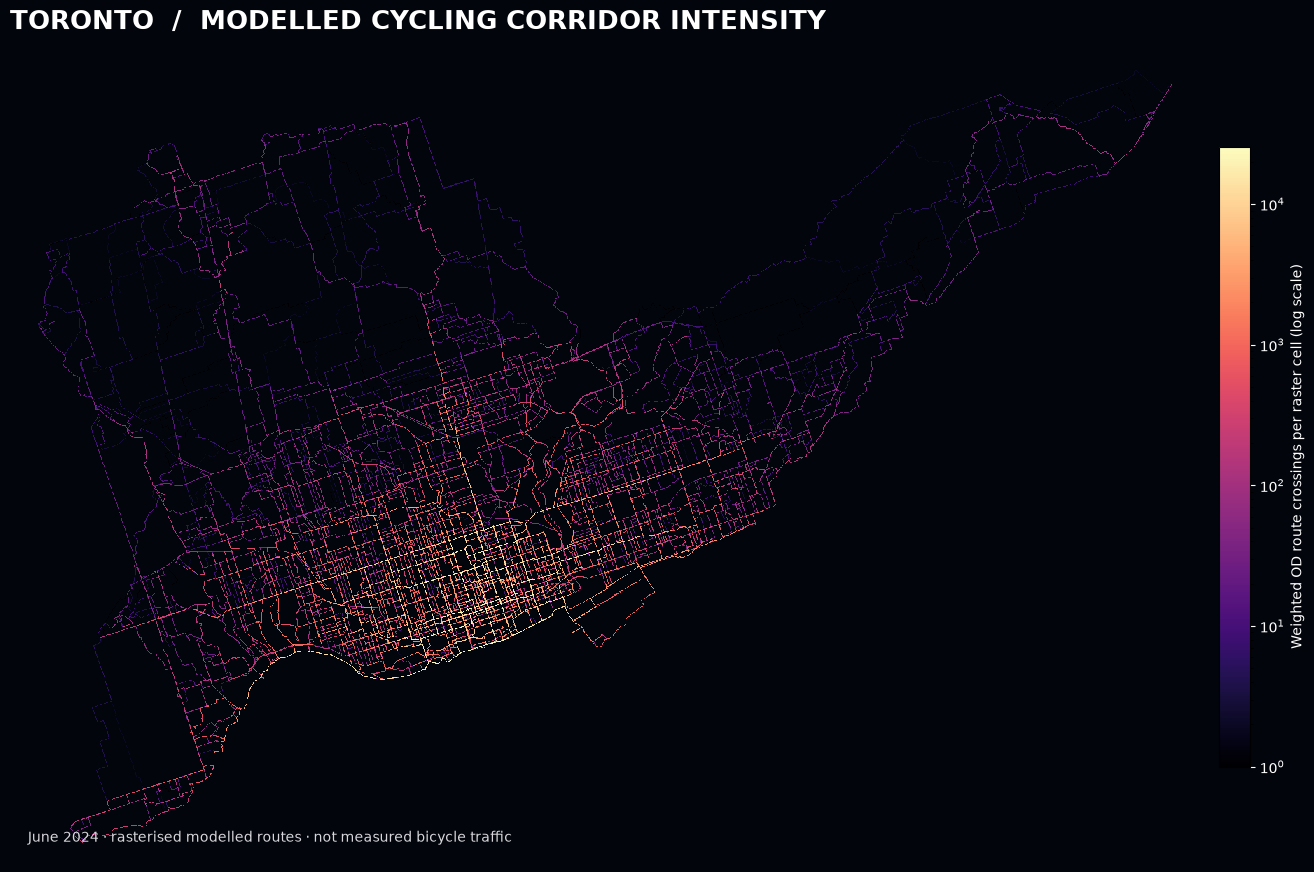

Nonzero cells: 87853 Peak cell weight: 55933.0


In [4]:
# Requires rasterio (common in CSC geospatial Python environments).
from rasterio.features import rasterize
from rasterio.enums import MergeAlg
from rasterio.transform import from_bounds

# Control spatial detail: increase WIDTH to 2200 for more resolution.
WIDTH, HEIGHT = 1700, 1300
xmin,ymin,xmax,ymax = gdf.total_bounds
pad_x, pad_y = (xmax-xmin)*.025, (ymax-ymin)*.025
extent = (xmin-pad_x, xmax+pad_x, ymin-pad_y, ymax+pad_y)
transform = from_bounds(extent[0], extent[2], extent[1], extent[3], WIDTH, HEIGHT)
# A route contributes its trip count once to each touched raster cell (per line geometry).
shapes = ((geom, float(n)) for geom,n in zip(gdf.geometry, gdf.trip_count)
          if geom is not None and not geom.is_empty)
intensity = rasterize(shapes, out_shape=(HEIGHT,WIDTH), transform=transform,
                      fill=0, dtype='float32', all_touched=False, merge_alg=MergeAlg.add)
positive = intensity[intensity>0]
fig, ax = plt.subplots(figsize=(16,12), facecolor='#02050b')
ax.set_facecolor('#02050b')
image = ax.imshow(np.ma.masked_less_equal(intensity,0), extent=extent,
                  origin='upper', cmap='magma', norm=LogNorm(vmin=1, vmax=max(2,np.quantile(positive,.995))),
                  interpolation='nearest')
ax.set_aspect('equal'); ax.set_axis_off()
ax.set_title('TORONTO  /  MODELLED CYCLING CORRIDOR INTENSITY', loc='left', color='white', fontsize=19, weight='bold', pad=16)
cb = fig.colorbar(image, ax=ax, fraction=.025, pad=.015, shrink=.72)
cb.set_label('Weighted OD route crossings per raster cell (log scale)', color='white')
cb.ax.tick_params(colors='white')
ax.text(.015,.025, 'June 2024 · rasterised modelled routes · not measured bicycle traffic',
        color='#d6d6dc', transform=ax.transAxes, fontsize=10)
fig.savefig(OUT/'map_B_corridor_intensity.png', dpi=220, facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show(); plt.close(fig)
print('Nonzero cells:',len(positive),'Peak cell weight:',float(positive.max()))


## Figure C — Recorded vs modelled trip duration
Use **all eligible individual trips**, rather than one point per OD pair. Dense hexagonal bins show the spread without overplotting hundreds of thousands of markers. Modelled times are based on GraphHopper travel-time assumptions and are **not** observed trip durations.

Trips joined to routes: 737,915
Observed duration below modelled time: 99,168 (13.4%)
       actual_min   time_min  difference_min
count   737915.00  737915.00       737915.00
mean        17.10       9.61            7.49
std         95.17       6.29           94.81
min          0.03       0.01          -37.36
10%          4.73       3.48           -0.33
50%         11.95       8.06            2.84
90%         29.10      17.73           13.45
99%         81.13      31.49           67.72
max      23234.70      95.73        23222.29


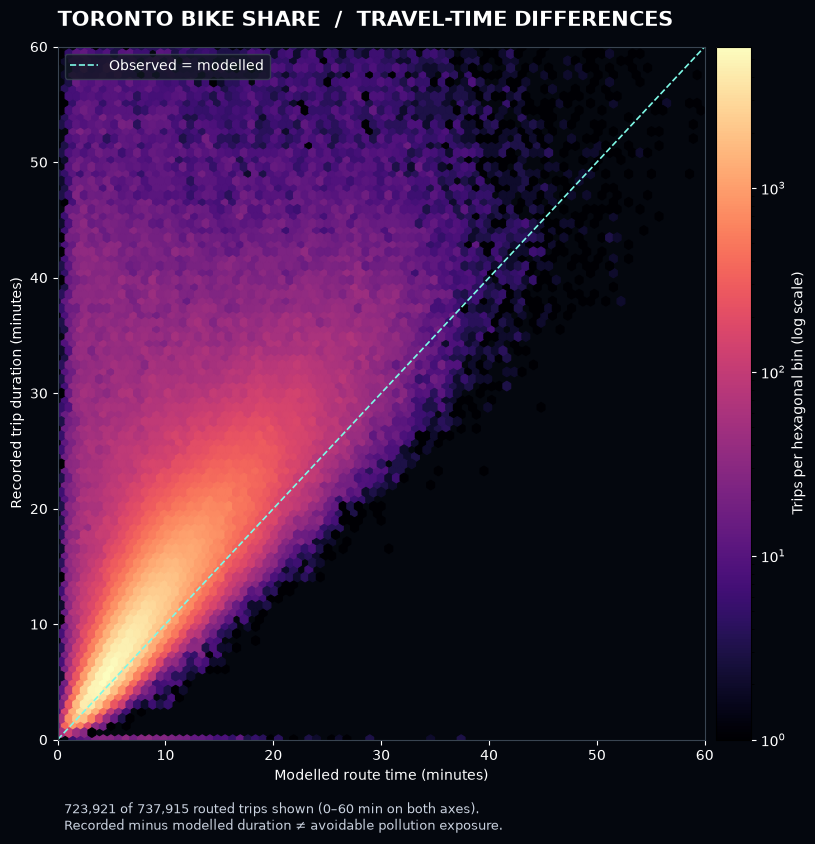

In [5]:
trips = pd.read_parquet(DATA/'bikeshare_june_2024_validated.parquet',
                        columns=['Trip_Id','Start_Station_Id','End_Station_Id','Trip_Duration'])
for c in ['Start_Station_Id','End_Station_Id']:
    trips[c] = trips[c].astype('string')
trips['Trip_Duration'] = pd.to_numeric(trips.Trip_Duration, errors='coerce')
# Same-station trips and nonpositive duration were excluded from routing.
trips = trips[trips.Trip_Duration.gt(0) & trips.Start_Station_Id.ne(trips.End_Station_Id)].copy()
joined = trips.merge(rd[['start_id','end_id','time_min','distance_m']],
                    left_on=['Start_Station_Id','End_Station_Id'],
                    right_on=['start_id','end_id'],how='inner',validate='many_to_one')
joined['actual_min'] = joined.Trip_Duration/60
joined['difference_min'] = joined.actual_min - joined.time_min
print(f'Trips joined to routes: {len(joined):,}')
print(f'Observed duration below modelled time: {(joined.difference_min<0).sum():,} ({(joined.difference_min<0).mean():.1%})')
print(joined[['actual_min','time_min','difference_min']].describe(percentiles=[.1,.5,.9,.99]).round(2))

# Clear view of typical journeys; always report exclusions due to limits.
plot_df = joined[joined.actual_min.between(0,60) & joined.time_min.between(0,60)].copy()
fig, ax = plt.subplots(figsize=(10,9), facecolor='#04070e')
ax.set_facecolor('#04070e')
hb = ax.hexbin(plot_df.time_min, plot_df.actual_min, gridsize=85,
               extent=(0,60,0,60), mincnt=1, bins='log', cmap='magma')
ax.plot([0,60],[0,60], ls='--', lw=1.2, color='#7ef9e7', label='Observed = modelled')
ax.set(xlim=(0,60),ylim=(0,60),xlabel='Modelled route time (minutes)',ylabel='Recorded trip duration (minutes)')
ax.set_title('TORONTO BIKE SHARE  /  TRAVEL-TIME DIFFERENCES', loc='left', color='white', fontsize=15, weight='bold', pad=15)
ax.tick_params(colors='white')
ax.xaxis.label.set_color('white'); ax.yaxis.label.set_color('white')
for spine in ax.spines.values(): spine.set_color('#394451')
leg=ax.legend(facecolor='#101820', edgecolor='#394451')
for t in leg.get_texts(): t.set_color('white')
cbar=fig.colorbar(hb,ax=ax,pad=.015)
cbar.set_label('Trips per hexagonal bin (log scale)',color='white');cbar.ax.tick_params(colors='white')
ax.text(.01,-.13,f'{len(plot_df):,} of {len(joined):,} routed trips shown (0–60 min on both axes).\nRecorded minus modelled duration ≠ avoidable pollution exposure.',
        transform=ax.transAxes,color='#c9d1de',fontsize=9)
fig.savefig(OUT/'figure_C_duration_hexbin.png',dpi=240,facecolor=fig.get_facecolor(),bbox_inches='tight')
plt.show();plt.close(fig)


## Outputs

- `outputs/maps/map_A_full_month_neon.png`
- `outputs/maps/map_B_corridor_intensity.png`
- `outputs/maps/figure_C_duration_hexbin.png`

**Interpretation before publication:** 2026 OSM network rather than historic 2024; station positions provisional; some 2024 trips excluded; same-station trips not reconstructed; modelled routing is not observed GPS; histogram differences do not measure avoidable environmental exposure.

Save this notebook to GitHub; keep output PNGs, SQLite and Parquet data in CSC storage.